In [56]:
from pathlib import Path
import os
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv

In [57]:
load_dotenv()

DATE_BEGIN = os.getenv('DATE_BEGIN')
DATE_END = os.getenv('DATE_END')
API_URL = os.getenv('API_URL')

In [58]:
resp1 = requests.get(
    f'{API_URL}/registrations',
    params={'begin': DATE_BEGIN, 'end': DATE_END}
)

resp2 = requests.get(
    f'{API_URL}/visits',
    params={'begin': DATE_BEGIN, 'end': DATE_END}
)

charts_dir = Path("charts")
charts_dir.mkdir(parents=True, exist_ok=True)


registrations = pd.DataFrame(resp1.json())
visits = pd.DataFrame(resp2.json())

In [94]:
visits = visits[
    ~visits['user_agent'].str.contains('bot', case=False, na=False)
].copy()

visits['datetime'] = pd.to_datetime(
    visits['datetime'],
    errors='coerce'
)

visits = visits.sort_values('datetime')

visits = visits.drop_duplicates(
    subset='visit_id',
    keep='last'
)

visits['date_group'] = visits['datetime'].dt.date


registrations['datetime'] = pd.to_datetime(
    registrations['datetime'],
    errors='coerce'
)

registrations['date_group'] = registrations['datetime'].dt.date

In [95]:
visits_grouped = (
    visits
    .groupby(['date_group', 'platform'])
    .size()
    .reset_index(name='visits')
)

registrations_grouped = (
    registrations
    .groupby(['date_group', 'platform'])
    .size()
    .reset_index(name='registrations')
)

conversion_df = pd.merge(
    visits_grouped,
    registrations_grouped,
    on=['date_group', 'platform'],
    how='left'
)

conversion_df['conversion'] = (
    conversion_df['registrations'] /
    conversion_df['visits'] * 100
)

conversion_df = conversion_df.sort_values(
    ['date_group', 'platform']
).reset_index(drop=True)

conversion_df['date_group'] = (
    pd.to_datetime(conversion_df['date_group'])
    .astype('int64') * 1000
)

display(conversion_df.head(20))

,date_group,platform,visits,registrations,conversion
0,1677628800000,android,75,61,81.333333
1,1677628800000,ios,22,18,81.818182
2,1677628800000,web,279,8,2.867384
3,1677715200000,android,67,59,88.059701
4,1677715200000,ios,31,24,77.419355
5,1677715200000,web,515,23,4.466019
6,1677801600000,android,26,22,84.615385
7,1677801600000,ios,40,34,85.000000
8,1677801600000,web,617,51,8.265802
9,1677888000000,android,94,77,81.914894


In [96]:
conversion_df.to_json(
    "./conversion.json", date_format="iso"
)

In [62]:
url = r"C:\Users\adminadmin\Desktop\hex\3\ads.csv"
ads = pd.read_csv(url)
display(ads.head())

,date,utm_source,utm_medium,utm_campaign,cost
0,2023-03-01T10:54:41,google,cpc,advanced_algorithms_series,212
1,2023-03-02T10:32:35,google,cpc,advanced_algorithms_series,252
2,2023-03-03T19:21:40,google,cpc,advanced_algorithms_series,202
3,2023-03-04T17:52:04,google,cpc,advanced_algorithms_series,223
4,2023-03-05T05:35:13,google,cpc,advanced_algorithms_series,265


In [63]:
ads["date"] = pd.to_datetime(ads["date"], errors="coerce")
ads["date_group"] = ads["date"].dt.strftime("%Y-%m-%d")

ads_grouped = (
    ads.groupby(["date_group", "utm_campaign"], as_index=False)
    ["cost"].sum()
)
display(ads_grouped.head())

,date_group,utm_campaign,cost
0,2023-03-01,advanced_algorithms_series,212
1,2023-03-02,advanced_algorithms_series,252
2,2023-03-03,advanced_algorithms_series,202
3,2023-03-04,advanced_algorithms_series,223
4,2023-03-05,advanced_algorithms_series,265


In [64]:
daily_metrics = (
    conversion_df
    .groupby("date_group", as_index=False)
    .agg({
        "visits": "sum",
        "registrations": "sum"
    })
)

daily_metrics["date_group"] = pd.to_datetime(
    daily_metrics["date_group"]
)

ads_grouped["date_group"] = pd.to_datetime(
    ads_grouped["date_group"]
)
ads_df = pd.merge(
    daily_metrics,
    ads_grouped,
    on="date_group",
    how="outer"
)


In [65]:
ads_df["visits"] = ads_df["visits"].fillna(0).astype(int)
ads_df["registrations"] = ads_df["registrations"].fillna(0).astype(int)
ads_df["cost"] = ads_df["cost"].fillna(0)
ads_df["utm_campaign"] = ads_df["utm_campaign"].fillna("none")
ads_df = ads_df[
    ["date_group", "visits", "registrations", "cost", "utm_campaign"]
]


In [66]:
ads_df["date_group"] = pd.to_datetime(
    ads_df["date_group"],
    errors="coerce"
)

In [67]:

ads_df = ads_df.sort_values("date_group").reset_index(drop=True)
display(ads_df.head(10))

,date_group,visits,registrations,cost,utm_campaign
0,1970-01-01 00:00:01.677628800,376,87,0.0,none
1,1970-01-01 00:00:01.677715200,613,106,0.0,none
2,1970-01-01 00:00:01.677801600,683,107,0.0,none
3,1970-01-01 00:00:01.677888000,647,159,0.0,none
4,1970-01-01 00:00:01.677974400,707,115,0.0,none
5,1970-01-01 00:00:01.678060800,1291,230,0.0,none
6,1970-01-01 00:00:01.678147200,1382,124,0.0,none
7,1970-01-01 00:00:01.678233600,1382,151,0.0,none
8,1970-01-01 00:00:01.678320000,1064,209,0.0,none
9,1970-01-01 00:00:01.678406400,812,112,0.0,none


In [68]:
ads_df.to_json(
    "ads.json",
    date_format = "iso"
)

In [69]:
import os

print("Файл сохранён:", os.path.exists("ads.json"))
print("Путь:", os.path.abspath("ads.json"))

Файл сохранён: True
Путь: C:\Users\adminadmin\ads.json


In [70]:
visits.to_json(
    "./visits.json",
    orient="records",
    date_format="iso",
    force_ascii=False,
    indent=2
)

In [71]:
registrations.to_json(
    "./registrations.json",
    orient="records",
    date_format="iso",
    force_ascii=False,
    indent=2
)

In [72]:
print(os.path.exists("./visits.json"))
print(os.path.exists("./registrations.json"))

True
True


In [73]:
print(ads_df.shape)
print(ads_df.dtypes)
display(ads_df.head())

(343, 5)
date_group       datetime64[ns]
visits                    int64
registrations             int64
cost                    float64
utm_campaign                str
dtype: object


,date_group,visits,registrations,cost,utm_campaign
0,1970-01-01 00:00:01.677628800,376,87,0.0,none
1,1970-01-01 00:00:01.677715200,613,106,0.0,none
2,1970-01-01 00:00:01.677801600,683,107,0.0,none
3,1970-01-01 00:00:01.677888000,647,159,0.0,none
4,1970-01-01 00:00:01.677974400,707,115,0.0,none


In [74]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [75]:
os.makedirs("./charts", exist_ok=True)

In [76]:
print(os.path.exists("./charts"))

True


In [77]:
visits["datetime"] = pd.to_datetime(visits["datetime"])
registrations["datetime"] = pd.to_datetime(registrations["datetime"])

visits["date_group"] = visits["datetime"].dt.strftime("%Y-%m-%d")
registrations["date_group"] = registrations["datetime"].dt.strftime("%Y-%m-%d")

conversion_df["date_group"] = pd.to_datetime(conversion_df["date_group"]).dt.strftime("%Y-%m-%d")
ads_df["date_group"] = pd.to_datetime(ads_df["date_group"]).dt.strftime("%Y-%m-%d")

import os

os.makedirs("./charts", exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["figure.dpi"] = 100

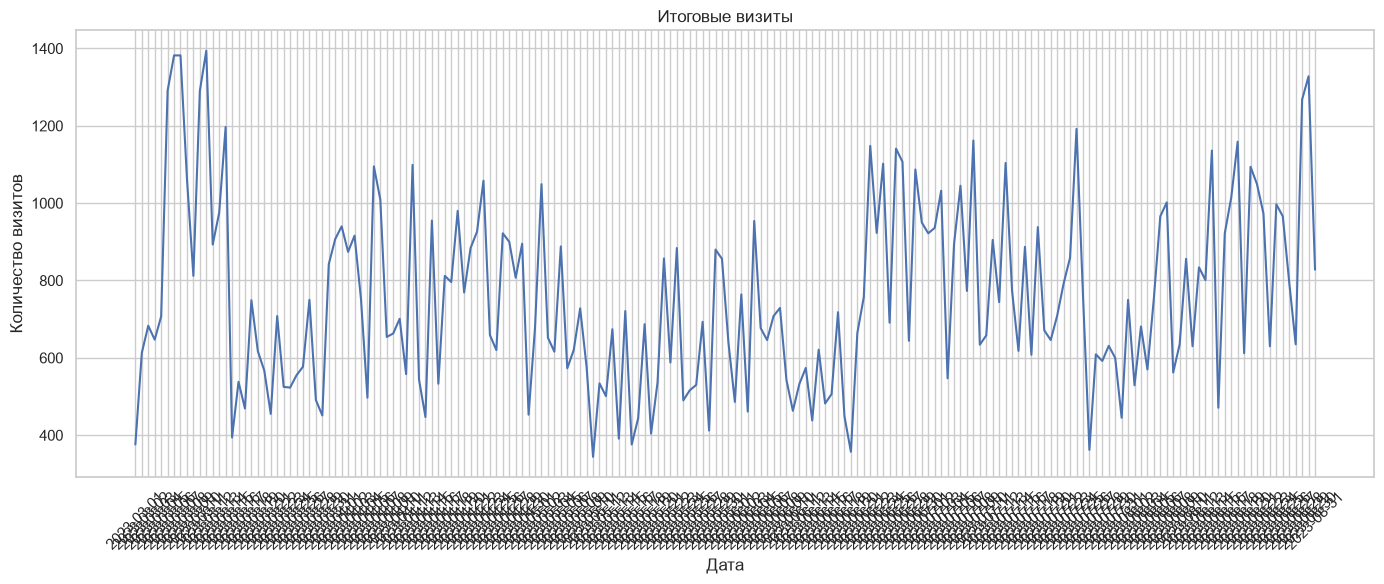

In [78]:
daily_visits = (
    visits
    .groupby("date_group")
    .size()
    .reset_index(name="visits")
)

plt.figure()

sns.lineplot(
    data=daily_visits,
    x="date_group",
    y="visits"
)

plt.title("Итоговые визиты")
plt.xlabel("Дата")
plt.ylabel("Количество визитов")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("./charts/total_visits.png")
plt.show()
plt.close()

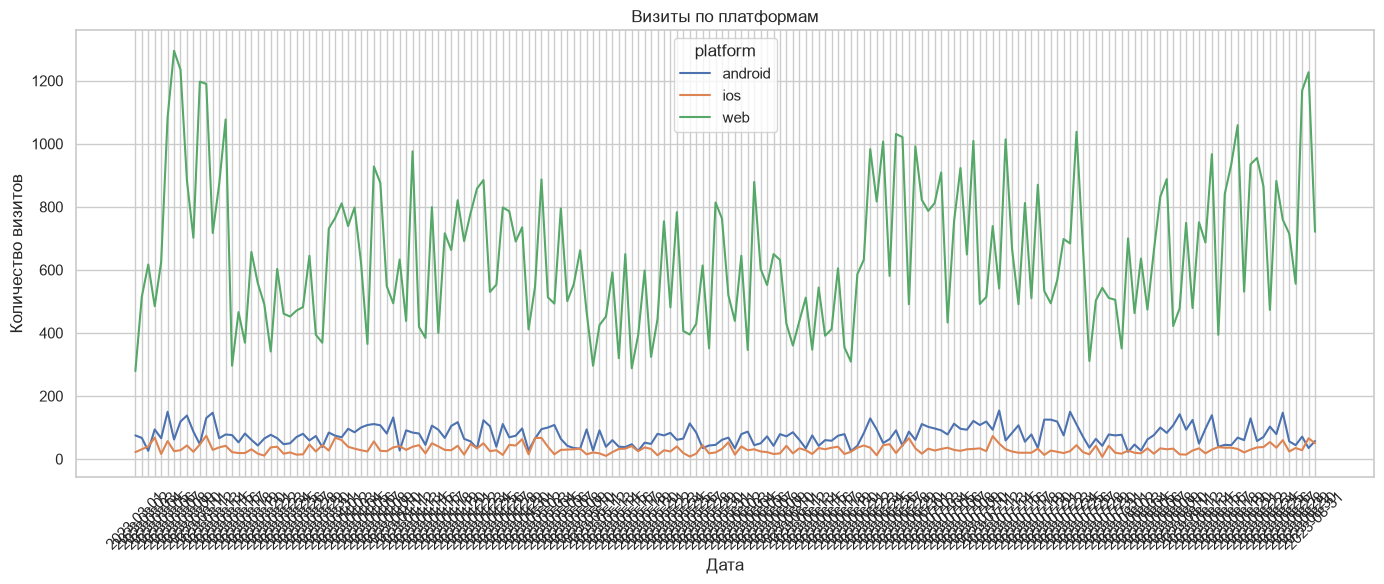

In [79]:
daily_visits_platform = (
    visits[visits["platform"].isin(["web", "android", "ios"])]
    .groupby(["date_group", "platform"])
    .size()
    .reset_index(name="visits")
)

plt.figure()

sns.lineplot(
    data=daily_visits_platform,
    x="date_group",
    y="visits",
    hue="platform"
)

plt.title("Визиты по платформам")
plt.xlabel("Дата")
plt.ylabel("Количество визитов")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("./charts/visits_by_platform.png")
plt.show()
plt.close()

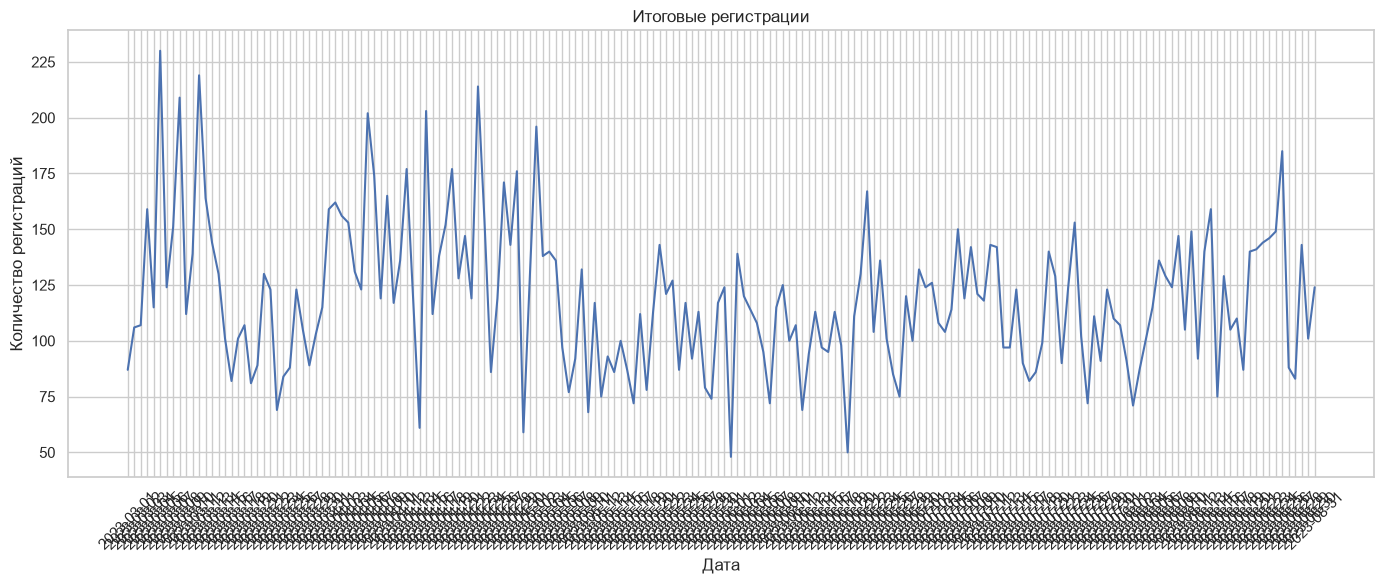

In [80]:
daily_registrations = (
    registrations
    .groupby("date_group")
    .size()
    .reset_index(name="registrations")
)

plt.figure()

sns.lineplot(
    data=daily_registrations,
    x="date_group",
    y="registrations"
)

plt.title("Итоговые регистрации")
plt.xlabel("Дата")
plt.ylabel("Количество регистраций")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(charts_dir / "total_registrations.png")
plt.show()
plt.close()

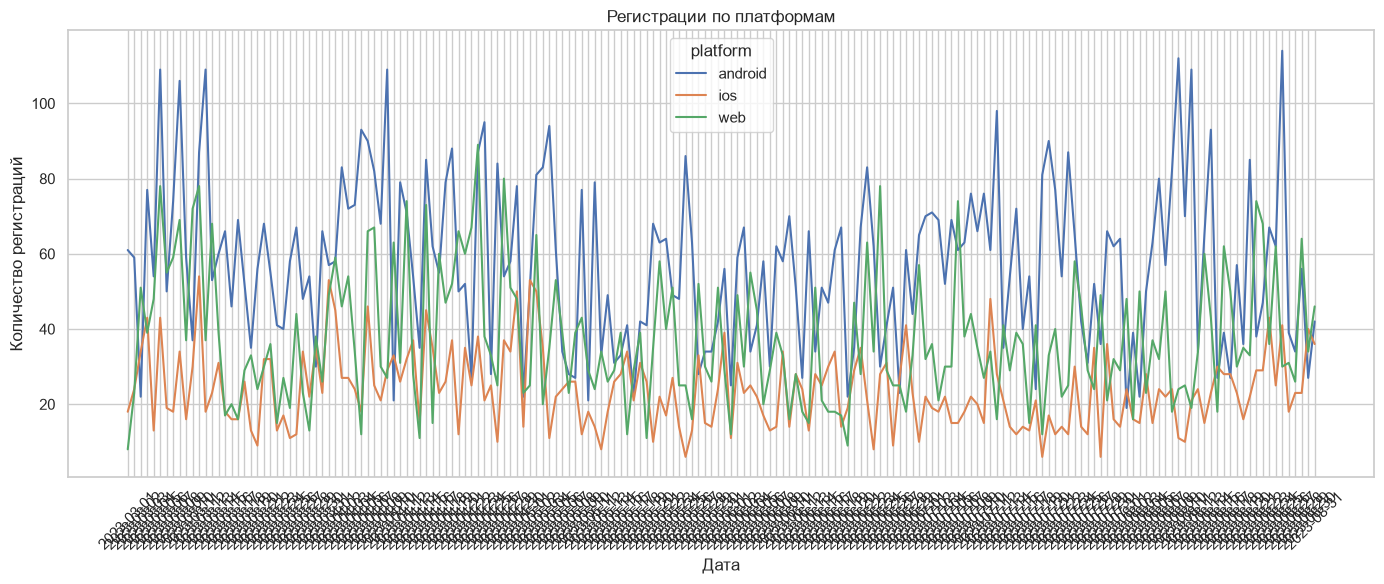

In [81]:
daily_registrations_platform = (
    registrations[registrations["platform"].isin(["web", "android", "ios"])]
    .groupby(["date_group", "platform"])
    .size()
    .reset_index(name="registrations")
)

plt.figure()

sns.lineplot(
    data=daily_registrations_platform,
    x="date_group",
    y="registrations",
    hue="platform"
)

plt.title("Регистрации по платформам")
plt.xlabel("Дата")
plt.ylabel("Количество регистраций")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(charts_dir / "registrations_by_platform.png")
plt.show()
plt.close()

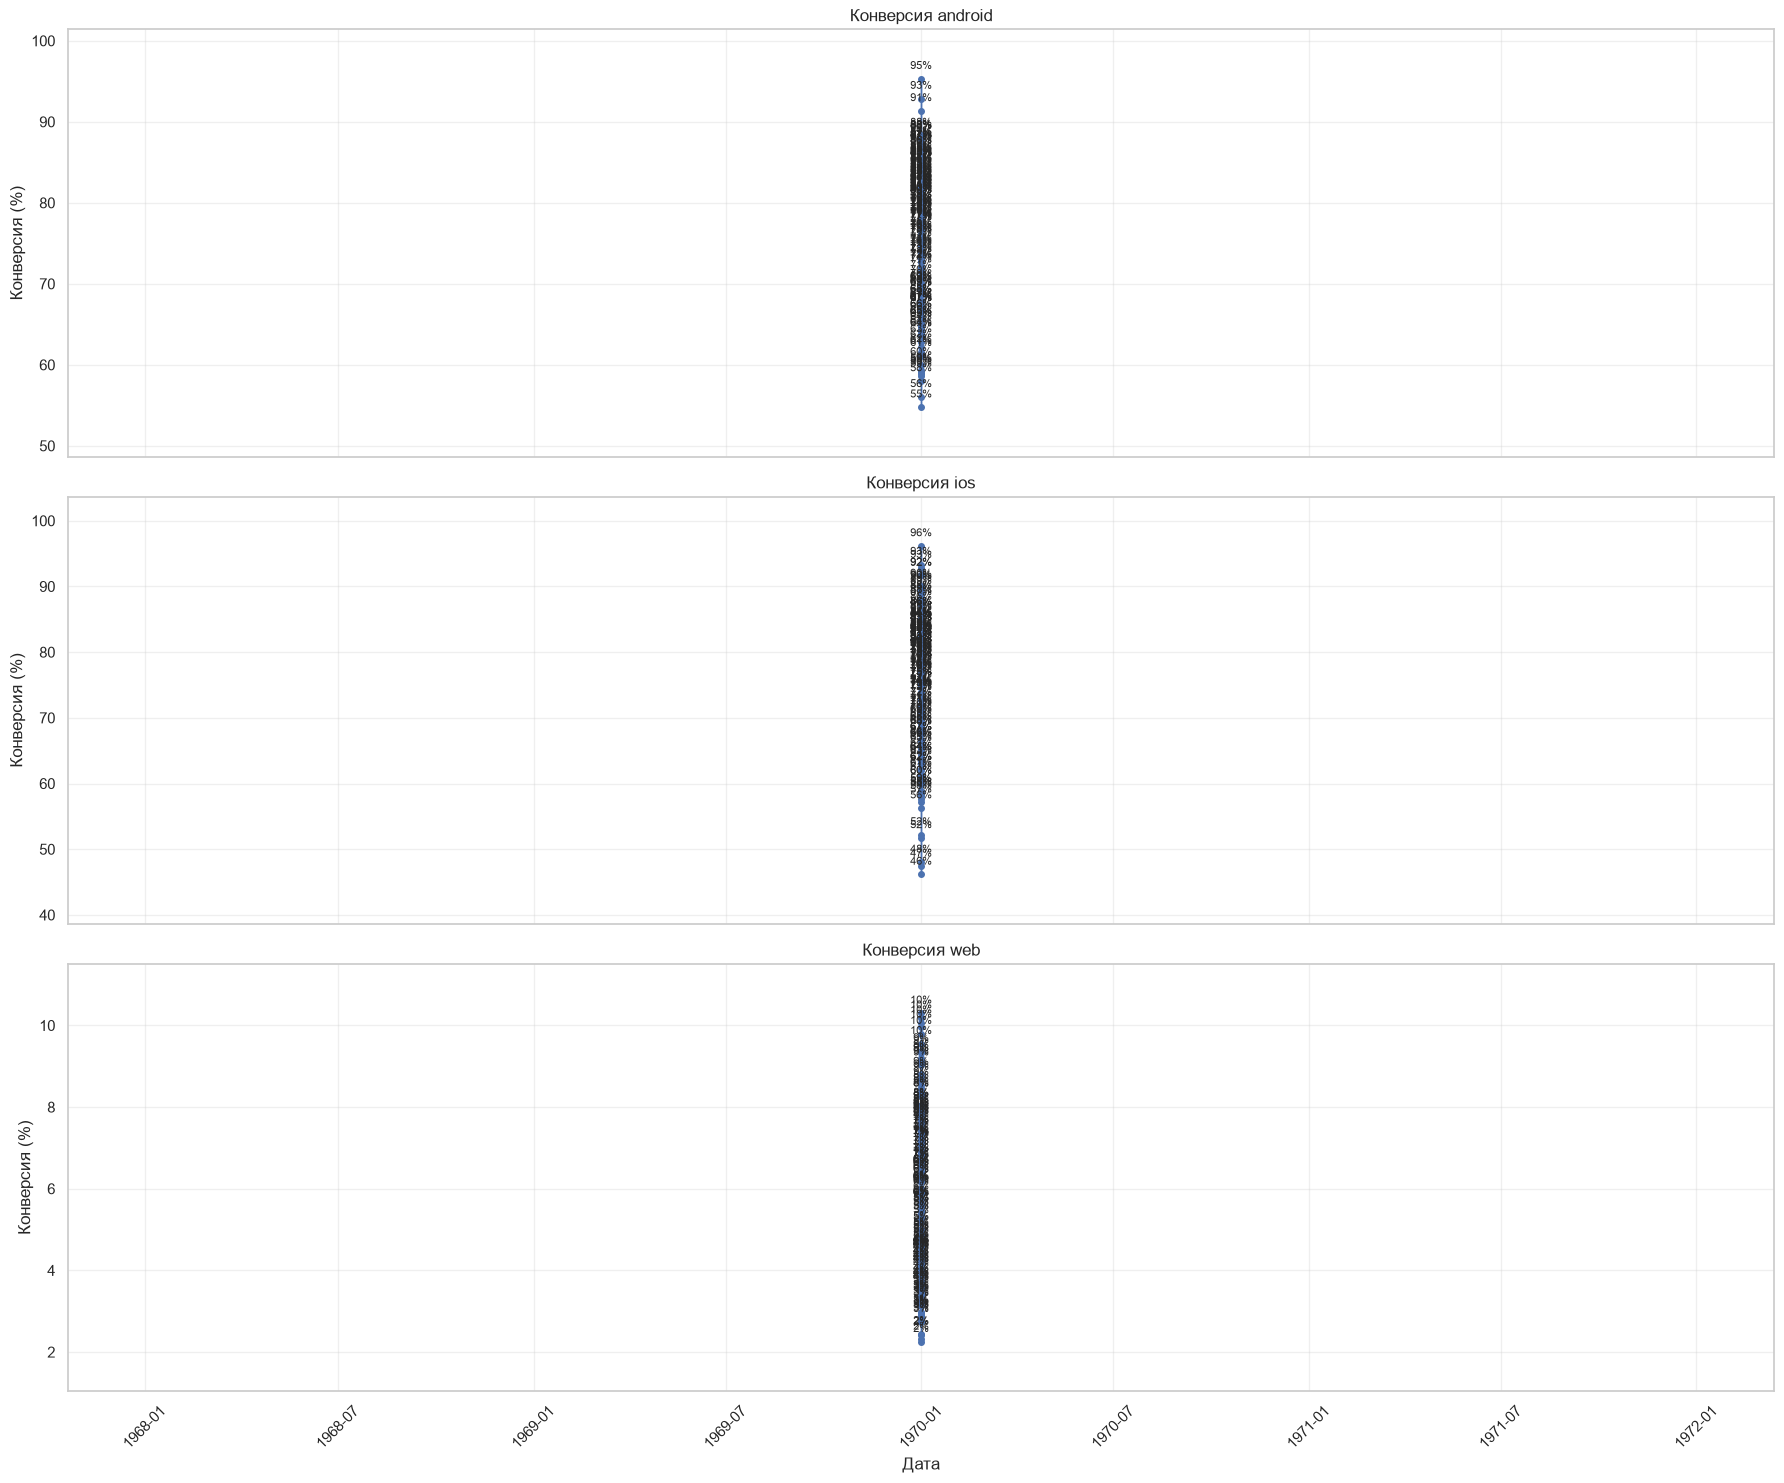

In [82]:
import matplotlib.pyplot as plt
import pandas as pd

# Подготавливаем даты
conversion_df["date_group"] = pd.to_datetime(conversion_df["date_group"])

# Платформы и порядок графиков
platforms = ["android", "ios", "web"]

# Создаём три графика друг под другом
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(18, 15),
    sharex=True
)

for ax, platform in zip(axes, platforms):

    platform_data = (
        conversion_df[conversion_df["platform"] == platform]
        .sort_values("date_group")
        .dropna(subset=["conversion"])
    )

    # Линия и точки
    ax.plot(
        platform_data["date_group"],
        platform_data["conversion"],
        marker="o",
        markersize=4,
        linewidth=1
    )

    # Подписи процентов возле каждой точки
    for _, row in platform_data.iterrows():
        ax.annotate(
            f'{row["conversion"]:.0f}%',
            (row["date_group"], row["conversion"]),
            textcoords="offset points",
            xytext=(0, 7),
            ha="center",
            fontsize=8
        )

    ax.set_title(f"Конверсия {platform}")
    ax.set_ylabel("Конверсия (%)")
    ax.grid(True, alpha=0.3)
    ax.margins(y=0.15)

axes[-1].set_xlabel("Дата")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(charts_dir / "conversion_by_platform.png")

plt.show()

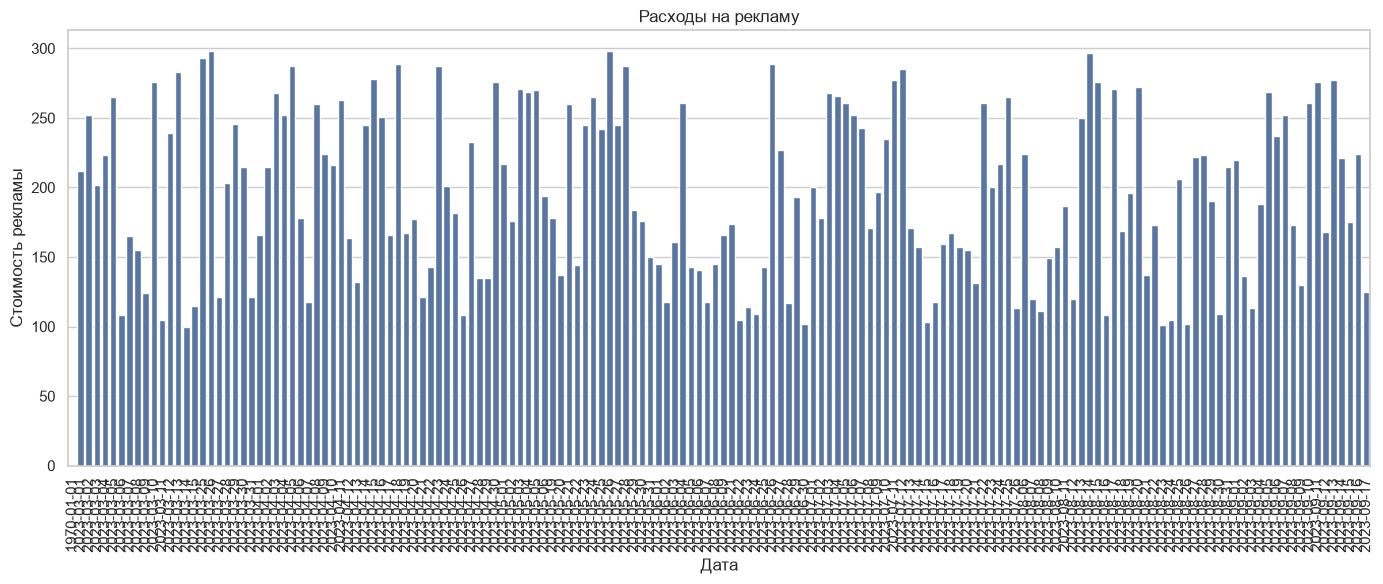

In [83]:
daily_cost = (
    ads_df
    .groupby("date_group")["cost"]
    .sum()
    .reset_index()
)

plt.figure()

sns.barplot(
    data=daily_cost,
    x="date_group",
    y="cost"
)

plt.title("Расходы на рекламу")
plt.xlabel("Дата")
plt.ylabel("Стоимость рекламы")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(charts_dir / "advertising_cos.png")
plt.show()
plt.close()

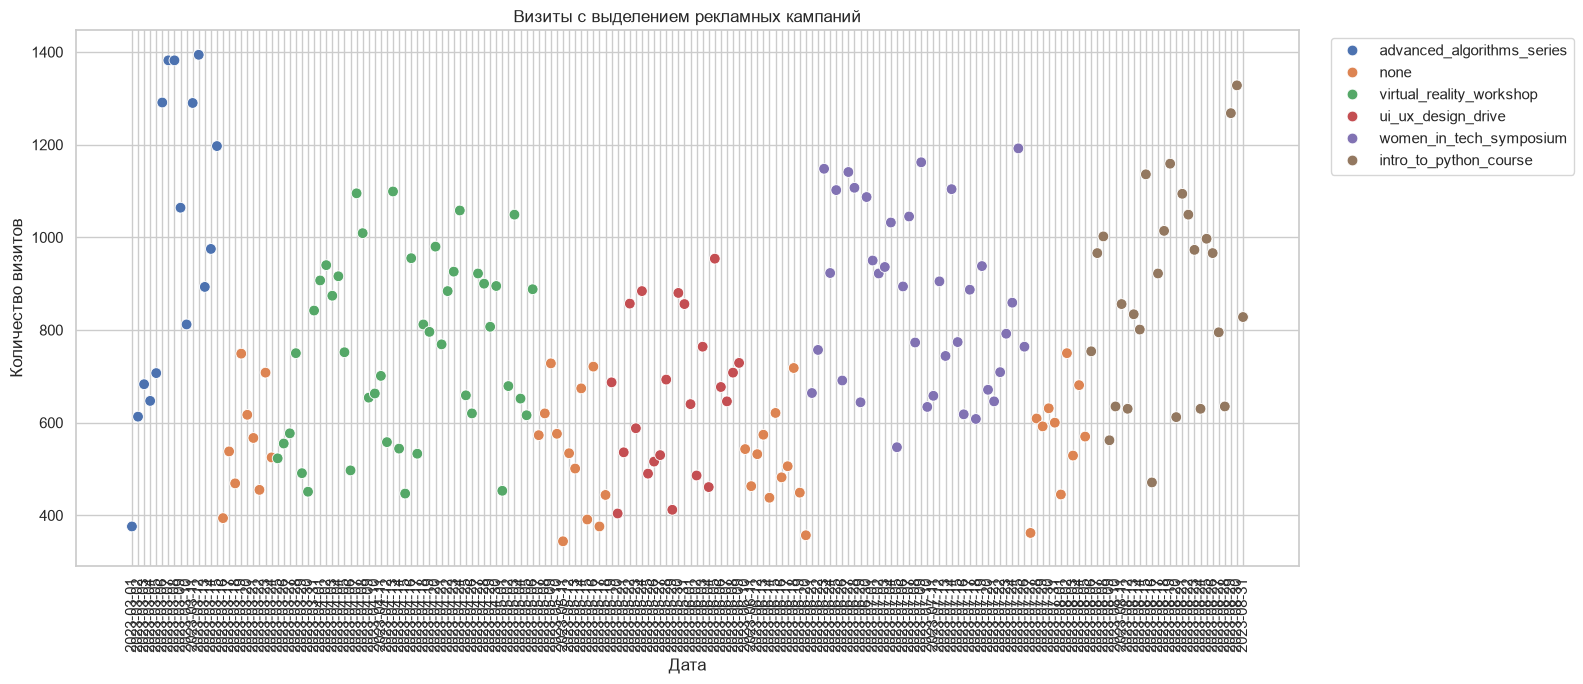

In [84]:
visits_ads = pd.merge(
    daily_visits,
    ads_df[["date_group", "utm_campaign"]],
    on="date_group",
    how="left"
)

visits_ads["utm_campaign"] = visits_ads["utm_campaign"].fillna("none")

plt.figure(figsize=(16, 7))

sns.scatterplot(
    data=visits_ads,
    x="date_group",
    y="visits",
    hue="utm_campaign",
    s=60
)

plt.title("Визиты с выделением рекламных кампаний")
plt.xlabel("Дата")
plt.ylabel("Количество визитов")
plt.xticks(rotation=90)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.savefig(charts_dir / "visits_by_campaign.png")
plt.show()
plt.close()

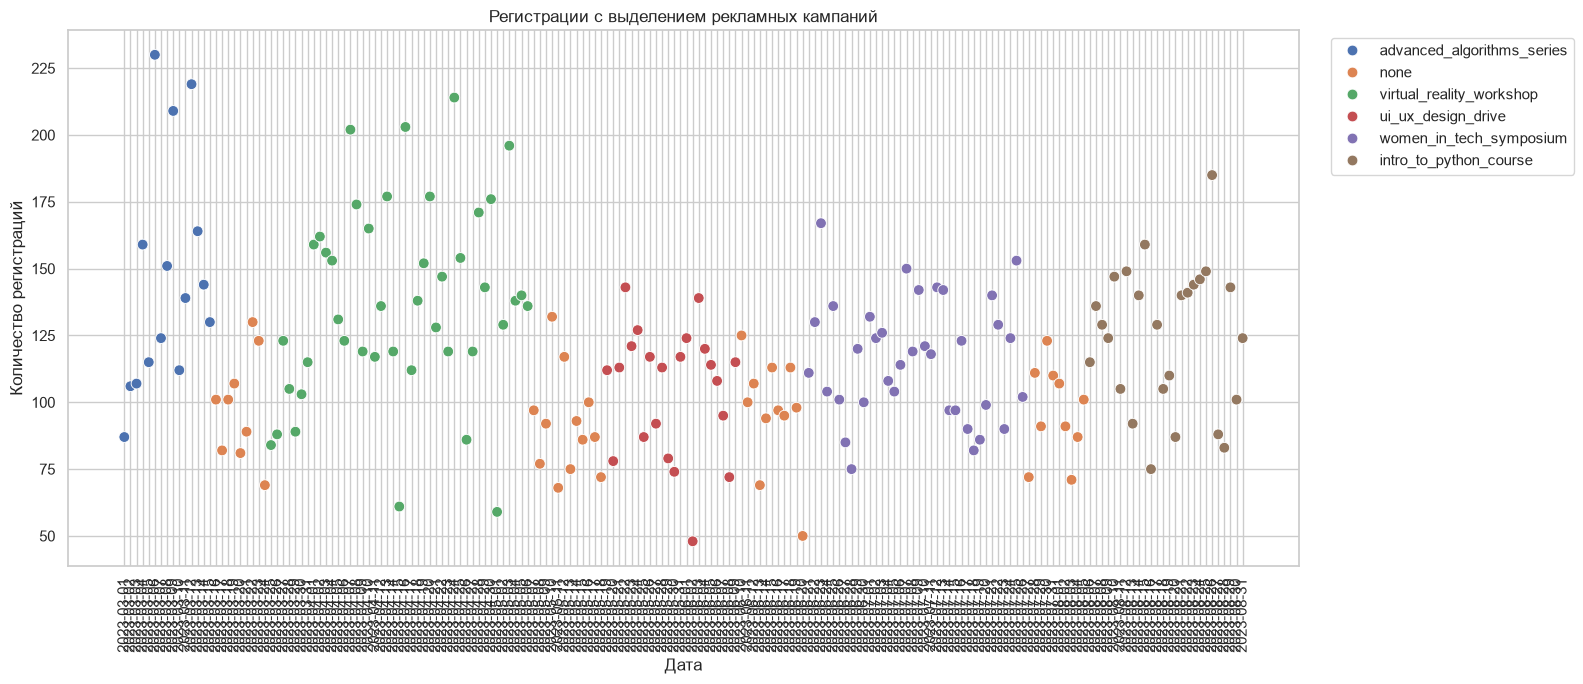

In [85]:
registrations_ads = pd.merge(
    daily_registrations,
    ads_df[["date_group", "utm_campaign"]],
    on="date_group",
    how="left"
)

registrations_ads["utm_campaign"] = registrations_ads["utm_campaign"].fillna("none")

plt.figure(figsize=(16, 7))

sns.scatterplot(
    data=registrations_ads,
    x="date_group",
    y="registrations",
    hue="utm_campaign",
    s=60
)

plt.title("Регистрации с выделением рекламных кампаний")
plt.xlabel("Дата")
plt.ylabel("Количество регистраций")
plt.xticks(rotation=90)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.savefig(charts_dir / "registrations_by_campaign.png")
plt.show()
plt.close()

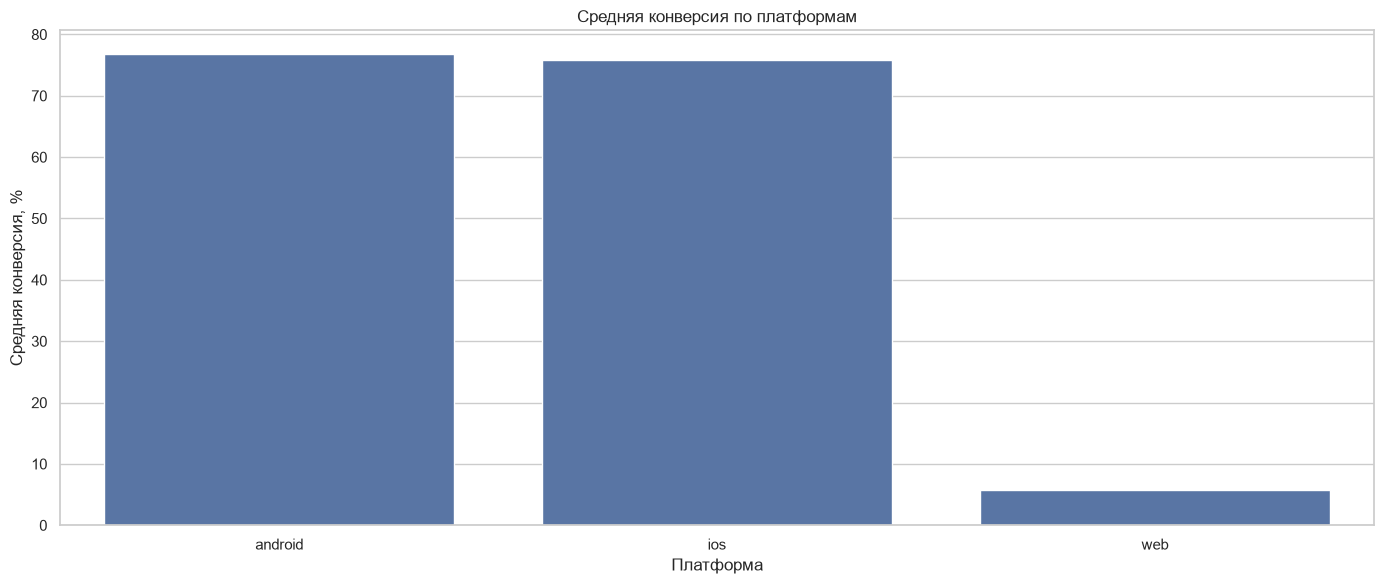

In [86]:
average_conversion = (
    conversion_df
    .groupby("platform")["conversion"]
    .mean()
    .reset_index()
)

plt.figure()

sns.barplot(
    data=average_conversion,
    x="platform",
    y="conversion"
)

plt.title("Средняя конверсия по платформам")
plt.xlabel("Платформа")
plt.ylabel("Средняя конверсия, %")
plt.tight_layout()


plt.savefig(charts_dir / "average_conversion.png")
plt.show()
plt.close()


In [87]:
print(os.listdir("./charts"))

['.ipynb_checkpoints', 'advertising_cos.png', 'advertising_cost.png', 'average_conversion.png', 'conversion_by_platform.png', 'registrations_by_campaign.png', 'registrations_by_platform.png', 'total_registrations.png', 'total_visits.png', 'visits_by_campaign.png', 'visits_by_platform.png']


In [88]:
import os
print(os.path.exists("./.env"))

True


In [89]:
from pathlib import Path

charts = list(Path("./charts").glob("*.png"))

print("Количество графиков:", len(charts))

for chart in sorted(charts):
    print(chart)

Количество графиков: 10
charts\advertising_cos.png
charts\advertising_cost.png
charts\average_conversion.png
charts\conversion_by_platform.png
charts\registrations_by_campaign.png
charts\registrations_by_platform.png
charts\total_registrations.png
charts\total_visits.png
charts\visits_by_campaign.png
charts\visits_by_platform.png


In [90]:
os.listdir("charts")

['.ipynb_checkpoints',
 'advertising_cos.png',
 'advertising_cost.png',
 'average_conversion.png',
 'conversion_by_platform.png',
 'registrations_by_campaign.png',
 'registrations_by_platform.png',
 'total_registrations.png',
 'total_visits.png',
 'visits_by_campaign.png',
 'visits_by_platform.png']

In [97]:
os.makedirs('charts', exist_ok=True)

plt.savefig('charts/conversion.png')
plt.close()